### Retrospective Labelling - Hyperparameter Tuning (PR-AUC)

* Using the findings of the best performing datasets in `model_compare_dataset`, I begin with hyperparameter tuning the model on its best performance

| Model | Transformation Variant | Dataset Variable |
| :--- | :--- | :--- |
| **LightGBM** | Raw | `train_raw` |
| **CatBoost** | Raw_removed_corr_var | `train_raw_removed_corr_var` |
| **Random Forest** | Raw_removed_corr_var | `train_raw_removed_corr_var` |
| **KNN** | YJ_robust_scaled | `train_yj_robust_scaled` |
| **Logistic Regression** | YJ_robust_scaled | `train_yj_robust_scaled` |
| **MLP Classifier** | YJ_robust_scaled | `train_yj_robust_scaled` |

* I ran randomised grid search on each model, and scored them by `neg_log_loss`
* Although the final metric for the model is evaluated in ROC-AUC, as this is just the data augmentation stage (augmenting NA rows with soft labels to become usable in the train dataset)
* I focus on neg_log_loss, as it reflects the the goal of predicting probabilities (soft labels)
* https://codemia.io/knowledge-hub/path/scikit-learn_classification_on_soft_labels
* https://leonidasgorgo.medium.com/understanding-roc-auc-and-pr-auc-c488faf45a16 
* I will move towards roc_auc tuning in the next stage

To control class imbalance:
* the train-test split is stratified by time_step and label - ensures an equal 20% representation of all illicit and licit in each time_step within the holdout (test) dataset
* Within the train split, Cross Vaildation is further stratified by `time_step` and `label`, to ensure representation of illicit datasets across all time_steps
----
#### Results
* Best Performing Model is LightGBM (performed the best on the holdout dataset (best PR_AUC, ROC_AUC, Precision, F1)), performance on Recall is onl second to CatBoost
* Best Parameters for LightGBM:
`{'model__scale_pos_weight': 3.0, 'model__num_leaves': 31, 'model__n_estimators': 500, 'model__min_child_samples': 50, 'model__max_depth': 20, 'model__learning_rate': 0.1}`
* to control for overfitting: comparing the CV pr-auc with the Holdout pr-auc, LightGBM performed better on the holdout dataset. If overfitting had occurred, LightGBM would have performed worse.

Note: Decision to keep Soft Labelling and not Hard Labelling
* https://arxiv.org/abs/2412.09579
* soft labeling consistently outperforms hard labeling in scenarios like knowledge distillation
* soft labelling allows me to tune the confidence level and sample weights during phase 2 - thus i prefer this



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

In [2]:
### Load data

train_raw = pd.read_csv("train_raw_node_info.csv", header = 0)
train_raw_removed_corr_var = pd.read_csv("train_raw_removed_corr_var.csv", header = 0)
train_yj_robust_scaled = pd.read_csv("train_yj_robust_scaled.csv", header = 0)

In [3]:
print(train_raw.columns)
print(train_raw_removed_corr_var.columns)
print(train_yj_robust_scaled.columns)

Index(['txId', 'time_step', 'feat_1', 'feat_2', 'feat_3', 'feat_4', 'feat_5',
       'feat_6', 'feat_7', 'feat_8',
       ...
       'feat_162', 'feat_163', 'feat_164', 'feat_165', 'label', 'in_degree',
       'out_degree', 'total_degree', 'degree_ratio', 'timestep_tx_volume'],
      dtype='object', length=173)
Index(['txId', 'time_step', 'label', 'feat_2', 'feat_3', 'feat_4', 'feat_5',
       'feat_7', 'feat_10', 'feat_12',
       ...
       'feat_160', 'feat_161', 'feat_162', 'feat_163', 'feat_164', 'in_degree',
       'out_degree', 'total_degree', 'degree_ratio', 'timestep_tx_volume'],
      dtype='object', length=110)
Index(['txId', 'time_step', 'feat_1', 'feat_2', 'feat_3', 'feat_4', 'feat_5',
       'feat_6', 'feat_7', 'feat_8',
       ...
       'feat_162', 'feat_163', 'feat_164', 'feat_165', 'label', 'in_degree',
       'out_degree', 'total_degree', 'degree_ratio', 'timestep_tx_volume'],
      dtype='object', length=173)


In [4]:
datasets = {
    "LightGBM": ("Raw", train_raw),
    "CatBoost": ("Raw_removed_corr_var", train_raw_removed_corr_var),
    "Random Forest": ("Raw_removed_corr_var", train_raw_removed_corr_var),
    "KNN": ("YJ_robust_scaled", train_yj_robust_scaled),
    "Logistic Regression": ("YJ_robust_scaled", train_yj_robust_scaled),
    "MLP Classifier": ("YJ_robust_scaled", train_yj_robust_scaled),
}


In [5]:
# Get numeric predictors in the same txId order as the split.
# time_step is included as a predictor; txId, index, and label are excluded.
def get_X_for_ids(df, ids):
    indexed = df.set_index("txId", drop=False)
    aligned = indexed.loc[list(ids)]

    excluded = {"txId", "index", "label"}
    feature_columns = [
        c for c in aligned.select_dtypes(include=np.number).columns
        if c not in excluded
    ]
    return aligned[feature_columns]

In [6]:
known = train_raw.loc[train_raw["label"].notna()].copy()
known["label"] = known["label"].astype(int)

strata = (
    known["time_step"].astype(str)
    + "_label_"
    + known["label"].astype(str)
)

stratum_counts = strata.value_counts()
if (stratum_counts < 2).any():
    raise ValueError("At least one time_step/label group has fewer than 2 rows.")

train_ids, test_ids = train_test_split(
    known["txId"],
    test_size=0.20,
    random_state=100,
    stratify=strata,
)

In [7]:

known_by_id = known.set_index("txId", drop=False)
train_id_list = list(train_ids) #for cross-validation
test_id_list = list(test_ids) #at the end, the holdout

y_dev = known_by_id.loc[train_id_list, "label"].astype(int)
y_holdout = known_by_id.loc[test_id_list, "label"].astype(int)

# Try to stratify CV folds by both time_step and label.
dev_time = known_by_id.loc[train_id_list, "time_step"].astype(str)
cv_strata = dev_time + "_label_" + y_dev.astype(str)

# If some time_step-label groups are too small for 3 folds,
# stratify by label alone instead.
if cv_strata.value_counts().min() >= 3:
    stratify_values = cv_strata
else:
    stratify_values = y_dev
    print("Using label-only stratification for CV because some time-step/label groups are small.")

n_splits = min(3, int(stratify_values.value_counts().min()))
if n_splits < 2:
    raise ValueError("Not enough examples per class/group for stratified CV.")

cv = list( #splits with statify_values - combination of time_step and label type - ensure consistent representation
    StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=100
    ).split(np.zeros(len(y_dev)), stratify_values)
)

# Use the training labels only to estimate the approximate negative:positive ratio.
# for lightBGM params to control imbalance
positive_weight = (y_dev == 0).sum() / (y_dev == 1).sum()

print("Positive weight: ", positive_weight)

Positive weight:  7.57221269296741


In [8]:
C_values = [0.01, 0.1, 1, 10, 100]

search_specs = {
    "Logistic Regression": {
        "estimator": LogisticRegression(
            max_iter=3000,
            random_state=100,
        ),
        "params": [
            {
                "model__solver": ["lbfgs"],
                "model__penalty": ["l2"],
                "model__C": C_values,
            },
            {
                "model__solver": ["lbfgs"],
                "model__penalty": [None],
                "model__C": [1.0], # dummy value
            },
            {
                "model__solver": ["liblinear"],
                "model__penalty": ["l1", "l2"],
                "model__C": C_values,
            },
            {
                "model__solver": ["saga"],
                "model__penalty": ["l1", "l2"],
                "model__C": C_values,
            },
            {
                "model__solver": ["saga"],
                "model__penalty": ["elasticnet"],
                "model__l1_ratio": [0.5],
                "model__C": C_values,
            },
        ],
        "n_iter": 31, # all combinations
    },

    "LightGBM": {
        "estimator": LGBMClassifier(
            objective="binary", # for binary classification
            random_state=100,
            verbosity=-1,
            n_jobs=-1,
        ),
        "params": {
            "model__n_estimators": [100, 300, 500],
            "model__learning_rate": [0.03, 0.05, 0.1],
            "model__num_leaves": [15, 31, 63], # 2^4 - 1 = 15, 2^5 - 1 = 31, etc
            "model__max_depth": [-1, 10, 20],
            "model__min_child_samples": [20, 50],
            "model__scale_pos_weight": [1.0, 3.0, 5.0, 8.0],
        },
        "n_iter": 240,
    },

    "CatBoost": {
        "estimator": CatBoostClassifier(
            loss_function="Logloss",
            eval_metric="F1",
            random_seed=100,
            verbose=0,
            allow_writing_files=False,
            thread_count=-1,
        ),
        "params": [
            # Unweighted configurations
            {
                "model__iterations": [300, 500, 800],
                "model__depth": [4, 6, 8],
                "model__learning_rate": [0.03, 0.05, 0.1],
                "model__l2_leaf_reg": [3, 5, 10],
            },

            # Balanced configurations
            {
                "model__iterations": [300, 500, 800],
                "model__depth": [4, 6, 8],
                "model__learning_rate": [0.03, 0.05, 0.1],
                "model__l2_leaf_reg": [3, 5, 10],
                "model__auto_class_weights": ["Balanced"],
            },
        ],
        "n_iter": 80,
    },

    "Random Forest": {
        "estimator": RandomForestClassifier(
            random_state=100,
            n_jobs=-1,
        ),
        "params": {
            "model__n_estimators": [100, 200, 400],
            "model__max_depth": [None, 15, 30],
            "model__min_samples_split": [2, 10],
            "model__min_samples_leaf": [1, 5],
            "model__max_features": ["sqrt", 0.5],
            "model__class_weight": [None, "balanced", "balanced_subsample"],
        },
        "n_iter": 80,
    },

    "KNN": {
        "estimator": KNeighborsClassifier(n_jobs=-1),
        "params": {
            "model__n_neighbors": [3, 5, 7, 11, 15],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2],
        },
        "n_iter": 20, # all combinations
    },

    "MLP Classifier": {
        "estimator": MLPClassifier(
            random_state=100,
            max_iter=3000,
        ),
        "params": {
            "model__hidden_layer_sizes": [
                (50,),
                (100,),
                (100, 50),
            ],
            "model__alpha": [0.0001, 0.001, 0.01],
            "model__learning_rate_init": [0.0005, 0.001, 0.005],
            "model__activation": ["relu", "tanh"],
        },
        "n_iter": 40,
    },
}

In [ ]:
best_models = {}
X_holdouts = {}
results = []
all_cv_results = []

for model_name, (dataset_name, df) in datasets.items():
    print(f"Tuning {model_name} on {dataset_name}...")

    X_dev_model = get_X_for_ids(
        df,
        train_id_list,
    )

    X_holdout_model = get_X_for_ids(
        df,
        test_id_list,
    )

    spec = search_specs[model_name]

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", clone(spec["estimator"])),
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=spec["params"],
        n_iter=spec["n_iter"],
        scoring="neg_log_loss",
        cv=cv,
        refit=True,
        random_state=100,
        n_jobs=1,
        verbose=1,
        error_score="raise",
        return_train_score=True,
    )

    search.fit(X_dev_model, y_dev)
    
    best_model = search.best_estimator_
    best_models[model_name] = best_model

    # Keep holdout features for the separate evaluation cell.
    X_holdouts[model_name] = X_holdout_model

    # Save CV results for every configuration tried.
    cv_results = pd.DataFrame(search.cv_results_)
    cv_results.insert(0, "model", model_name)
    cv_results.insert(1, "dataset", dataset_name)
    cv_results["params"] = cv_results["params"].apply(repr)
    all_cv_results.append(cv_results)

    # Save this model's selected configuration summary.
    results.append({
        "model": model_name,
        "dataset": dataset_name,
        "best_cv_average_precision_mean": search.best_score_,
        "best_cv_average_precision_std": (
            search.cv_results_["std_test_score"][search.best_index_]
        ),
        "best_params": repr(search.best_params_),
    })

# After the loop finishes:
results_df = pd.DataFrame(results)
display(results_df)

all_cv_results_df = pd.concat(all_cv_results, ignore_index=True)
all_cv_results_df = all_cv_results_df.sort_values(
    ["model", "rank_test_score"]
)
all_cv_results_df.to_csv(
    "all_hyperparameter_cv_results.csv",
    index=False,
)

Tuning LightGBM on Raw...
Fitting 3 folds for each of 240 candidates, totalling 720 fits
Tuning CatBoost on Raw_removed_corr_var...
Fitting 3 folds for each of 80 candidates, totalling 240 fits
Tuning Random Forest on Raw_removed_corr_var...
Fitting 3 folds for each of 80 candidates, totalling 240 fits
Tuning KNN on YJ_robust_scaled...
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Tuning Logistic Regression on YJ_robust_scaled...
Fitting 3 folds for each of 31 candidates, totalling 93 fits
Tuning MLP Classifier on YJ_robust_scaled...
Fitting 3 folds for each of 40 candidates, totalling 120 fits


,model,dataset,best_cv_average_precision_mean,best_cv_average_precision_std,best_params
0,LightGBM,Raw,0.994233,0.001120,"{'model__scale_pos_weight': 3.0, 'model__num_l..."
1,CatBoost,Raw_removed_corr_var,0.992588,0.001186,"{'model__learning_rate': 0.1, 'model__l2_leaf_..."
2,Random Forest,Raw_removed_corr_var,0.990204,0.001361,"{'model__n_estimators': 400, 'model__min_sampl..."
3,KNN,YJ_robust_scaled,0.929534,0.008122,"{'model__weights': 'distance', 'model__p': 1, ..."
4,Logistic Regression,YJ_robust_scaled,0.951687,0.008029,"{'model__solver': 'liblinear', 'model__penalty..."
5,MLP Classifier,YJ_robust_scaled,0.927344,0.000583,"{'model__learning_rate_init': 0.001, 'model__h..."


In [12]:
print("Best parameters by model:")

for _, row in results_df.iterrows():
    print(f"\nModel: {row['model']}")
    print(f"Dataset: {row['dataset']}")
    print(f"Best CV PR-AUC: {row['best_cv_average_precision_mean']:.6f}")
    print("Best parameters:")
    print(row["best_params"])

Best parameters by model:

Model: LightGBM
Dataset: Raw
Best CV PR-AUC: 0.994233
Best parameters:
{'model__scale_pos_weight': 3.0, 'model__num_leaves': 31, 'model__n_estimators': 500, 'model__min_child_samples': 50, 'model__max_depth': 20, 'model__learning_rate': 0.1}

Model: CatBoost
Dataset: Raw_removed_corr_var
Best CV PR-AUC: 0.992588
Best parameters:
{'model__learning_rate': 0.1, 'model__l2_leaf_reg': 3, 'model__iterations': 800, 'model__depth': 6, 'model__auto_class_weights': 'Balanced'}

Model: Random Forest
Dataset: Raw_removed_corr_var
Best CV PR-AUC: 0.990204
Best parameters:
{'model__n_estimators': 400, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': None, 'model__class_weight': 'balanced'}

Model: KNN
Dataset: YJ_robust_scaled
Best CV PR-AUC: 0.929534
Best parameters:
{'model__weights': 'distance', 'model__p': 1, 'model__n_neighbors': 15}

Model: Logistic Regression
Dataset: YJ_robust_scaled
Best CV PR-AUC: 0.9

In [20]:
temp = all_cv_results_df.sort_values(by = ["model", "mean_test_score", "std_test_score"], ascending = [True, False, True]).groupby("model").head(4)
temp = temp[["model", "dataset", "params","mean_test_score","std_test_score","rank_test_score"]]
pd.set_option("display.max_colwidth", None)
display(temp)

,model,dataset,params,mean_test_score,std_test_score,rank_test_score
285,CatBoost,Raw_removed_corr_var,"{'model__learning_rate': 0.1, 'model__l2_leaf_reg': 3, 'model__iterations': 800, 'model__depth': 6, 'model__auto_class_weights': 'Balanced'}",0.992588,0.001186,1
268,CatBoost,Raw_removed_corr_var,"{'model__learning_rate': 0.05, 'model__l2_leaf_reg': 3, 'model__iterations': 800, 'model__depth': 6}",0.992580,0.001273,2
290,CatBoost,Raw_removed_corr_var,"{'model__learning_rate': 0.05, 'model__l2_leaf_reg': 3, 'model__iterations': 800, 'model__depth': 8}",0.992576,0.001037,3
288,CatBoost,Raw_removed_corr_var,"{'model__learning_rate': 0.1, 'model__l2_leaf_reg': 5, 'model__iterations': 800, 'model__depth': 8}",0.992455,0.000814,4
417,KNN,YJ_robust_scaled,"{'model__weights': 'distance', 'model__p': 1, 'model__n_neighbors': 15}",0.929534,0.008122,1
413,KNN,YJ_robust_scaled,"{'model__weights': 'distance', 'model__p': 1, 'model__n_neighbors': 11}",0.926505,0.009153,2
409,KNN,YJ_robust_scaled,"{'model__weights': 'distance', 'model__p': 1, 'model__n_neighbors': 7}",0.920471,0.010137,3
416,KNN,YJ_robust_scaled,"{'model__weights': 'uniform', 'model__p': 1, 'model__n_neighbors': 15}",0.920191,0.008094,4
158,LightGBM,Raw,"{'model__scale_pos_weight': 3.0, 'model__num_leaves': 31, 'model__n_estimators': 500, 'model__min_child_samples': 50, 'model__max_depth': 20, 'model__learning_rate': 0.1}",0.994233,0.001120,1
53,LightGBM,Raw,"{'model__scale_pos_weight': 3.0, 'model__num_leaves': 31, 'model__n_estimators': 300, 'model__min_child_samples': 50, 'model__max_depth': 20, 'model__learning_rate': 0.1}",0.994196,0.001136,2


standard deviation is roughly consistent between parameter variations, mean roc_auc score is roughly similar as well

* CatBoost, LightBGM have one of the lowest standard deviations and one of the highest mean roc_auc score
* however, LightBGM performs slightly better than CatBoost

In [14]:
holdout_results = []
holdout_curves = {}

for model_name, best_model in best_models.items():
    X_holdout = X_holdouts[model_name]

    holdout_scores = best_model.predict_proba(X_holdout)[:, 1]
    holdout_predictions = best_model.predict(X_holdout)

    precision_curve, recall_curve, _ = precision_recall_curve(
        y_holdout,
        holdout_scores,
        pos_label=1,
    )

    holdout_ap = average_precision_score(y_holdout, holdout_scores)

    holdout_curves[model_name] = {
        "precision": precision_curve,
        "recall": recall_curve,
        "average_precision": holdout_ap,
    }

    holdout_results.append({
        "model": model_name,
        "holdout_ROC_AUC": roc_auc_score(y_holdout, holdout_scores),
        "holdout_PR_AUC": holdout_ap,
        "holdout_precision": precision_score(
            y_holdout, holdout_predictions, zero_division=0
        ),
        "holdout_recall": recall_score(
            y_holdout, holdout_predictions, zero_division=0
        ),
        "holdout_F1": f1_score(
            y_holdout, holdout_predictions, zero_division=0
        ),
    })

holdout_results_df = pd.DataFrame(holdout_results).sort_values(
    "holdout_F1",
    ascending=False,
)
display(holdout_results_df)

,model,holdout_ROC_AUC,holdout_PR_AUC,holdout_precision,holdout_recall,holdout_F1
0,LightGBM,0.998921,0.996113,0.992958,0.967078,0.979847
1,CatBoost,0.998771,0.994701,0.979310,0.973937,0.976616
2,Random Forest,0.998592,0.993039,0.989645,0.917695,0.952313
5,MLP Classifier,0.971251,0.932054,0.989164,0.876543,0.929455
4,Logistic Regression,0.991188,0.960210,0.926346,0.897119,0.911498
3,KNN,0.970773,0.935032,0.898630,0.899863,0.899246


As per results of performance on the holdout dataset using the best parameters, LightGBM is selected due to its highest F1, Precision, PR_AUC and ROC_AUC

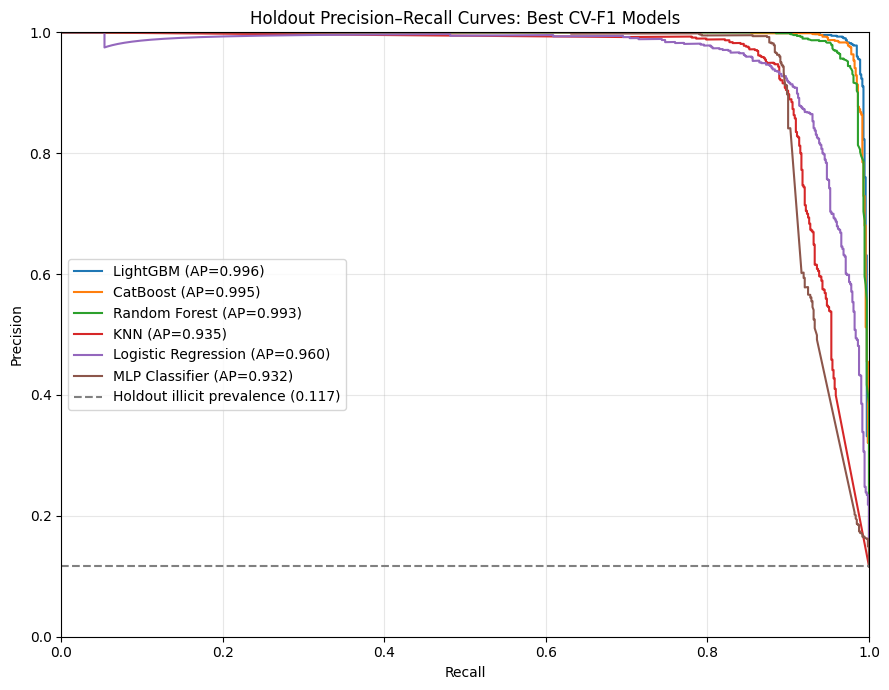

In [15]:
plt.figure(figsize=(9, 7))

for model_name, curve in holdout_curves.items():
    plt.plot(
        curve["recall"],
        curve["precision"],
        label=(
            f"{model_name} "
            f"(AP={curve['average_precision']:.3f})"
        ),
    )

# No-skill reference: the positive-class prevalence in the holdout.
plt.axhline(
    y=y_holdout.mean(),
    color="gray",
    linestyle="--",
    label=f"Holdout illicit prevalence ({y_holdout.mean():.3f})",
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Holdout Precision–Recall Curves: Best CV-F1 Models")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend(loc="best")
plt.tight_layout()
plt.show()